# DSA5205 — Nine Strategy Comparison (3 Momentum + 4 Ridge + SPY/QQQ)

Adds **B3_MomentumDoubleSort10**, the original momentum benchmark: first construct the 30-stock Momentum × Volatility 3×3 candidate pool, then select its 10 highest MOM2–12 stocks at equal weights. All other eight strategies are unchanged.

**Train:** 2010–2019; **validation:** 2020–2021; **test:** 2022–2025. **Target:** forward holding-period return (decimal). **Primary comparison:** post-cost annualized return; also report Sharpe, drawdown, turnover and prediction metrics.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

# Change only this path if your project folder has a different name.
PROJECT_ROOT = Path('/Users/hc/Desktop/NUS DSML/DSA 5205/Project2/DSA-5205/DSA5205_Project2_FINAL')
# Prefer notebook's parent project if it exists, otherwise the explicit path.
try:
    here = Path.cwd()
    for candidate in [here, here.parent]:
        if (candidate/'src'/'pipeline.py').exists(): PROJECT_ROOT=candidate;break
except PermissionError:
    pass
assert (PROJECT_ROOT/'src'/'pipeline.py').exists(), f'Update PROJECT_ROOT: {PROJECT_ROOT}'
sys.path.insert(0,str(PROJECT_ROOT))
# Also import extension from the folder containing this notebook.
# Place strategies.py in PROJECT_ROOT beside run_pipeline.py.
assert (PROJECT_ROOT/'strategies.py').exists(), 'Copy strategies.py to project root'
from src.pipeline import decision_dates, attach_labels
from strategies import FEATURES, pools, capped, train_ridge, targets_for_date, simulate, performance
FREQUENCY='monthly' # 'quarterly' or 'semiannual'
COST_BPS=20
cfg=json.loads((PROJECT_ROOT/'config/pipeline.json').read_text())
cfg.update(rebalance_frequency=FREQUENCY,train_end_exclusive='2020-01-01',validation_end_exclusive='2022-01-01',test_end_exclusive='2026-01-01')
print(PROJECT_ROOT, FREQUENCY)

/Users/hc/Desktop/NUS DSML/DSA 5205/Project2/DSA-5205/DSA5205_Project2_Pipeline monthly


## 1. Read cached real market data and select each period’s ADV20 Top 300

In [2]:
panel=pd.read_parquet(PROJECT_ROOT/'data/processed_with_nan/full_feature_panel.parquet')
raw=pd.read_parquet(PROJECT_ROOT/'data/raw/market_data.parquet')
assert not raw.ticker.astype(str).str.startswith('SYN').any()
records=[];sixties=[];thirties=[];audit=[]
for d in decision_dates(panel,cfg):
    g=panel[(panel.date==d)&(~panel.ticker.isin(['SPY','QQQ']))].copy()
    g=g[(g.close>=cfg['min_price'])&(g.adv_20>=cfg['min_adv20'])&(g.coverage_252>=cfg['min_coverage'])&(g.coverage_63>=cfg['min_coverage'])&(g.coverage_21>=cfg['min_coverage'])]
    g=g[np.isfinite(g[FEATURES].to_numpy(float)).all(axis=1)]
    g=g.sort_values(['adv_20','ticker'],ascending=[False,True]).head(300)
    audit.append({'decision_date':d,'eligible':len(g),'ok':len(g)>=90})
    if len(g)<90:continue
    s60,s30=pools(g)
    records.append(g);sixties.append(s60);thirties.append(s30)
assert records,'No eligible periods'
top300=pd.concat(records,ignore_index=True)
s60=pd.concat(sixties,ignore_index=True)
s30=pd.concat(thirties,ignore_index=True)
display(pd.DataFrame(audit).tail())
print('Candidate dates:',top300.date.nunique())

,decision_date,eligible,ok
187,2025-08-29,300,True
188,2025-09-30,300,True
189,2025-10-31,300,True
190,2025-11-28,300,True
191,2025-12-31,300,True


Candidate dates: 192


## 2. Attach next-open → next-rebalance-open adjusted returns (without selecting on future labels)

In [3]:
# attach_labels expects decision_date derived from date; preserve every screened stock.
full=attach_labels(top300,panel,cfg)
labels=full[['decision_date','ticker','execution_date','label_end_date','target_forward_return','spy_return','qqq_return']]
s60=s60.assign(decision_date=s60.date).merge(labels,on=['decision_date','ticker'],validate='one_to_one')
s30=s30.assign(decision_date=s30.date).merge(labels,on=['decision_date','ticker'],validate='one_to_one')
full['decision_date']=pd.to_datetime(full.decision_date)
s60['decision_date']=pd.to_datetime(s60.decision_date)
s30['decision_date']=pd.to_datetime(s30.decision_date)
for x in [full,s60,s30]:x['label_end_date']=pd.to_datetime(x.label_end_date)
print('Labels missing in 60 candidate pool:',s60.target_forward_return.isna().sum())

Labels missing in 60 candidate pool: 0


## 3. Fit ONE Ridge model on 60 candidates per period; select alpha by validation MSE; final refit

,alpha,train_mse,validation_mse
4,1000.0,0.008003,0.021639
3,100.0,0.007965,0.021755
5,10000.0,0.008080,0.021780
2,10.0,0.007962,0.021808
1,1.0,0.007962,0.021816
0,0.1,0.007962,0.021816


Fit info: {'alpha': 1000.0, 'train_rows': 7080, 'validation_rows': 1320, 'refit_rows': 8520}


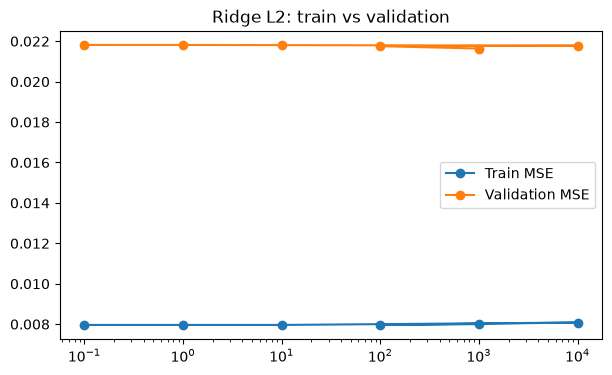

In [4]:
model,grid,fit_info=train_ridge(s60)
display(grid)
print('Fit info:',fit_info)
plt.figure(figsize=(7,4));plt.semilogx(grid.alpha,grid.train_mse,'o-',label='Train MSE');plt.semilogx(grid.alpha,grid.validation_mse,'o-',label='Validation MSE');plt.legend();plt.title('Ridge L2: train vs validation');plt.show()

## 4. Test: B1/B2/B3 and R1–R4, with same model and next-open execution

In [5]:
test_start=pd.Timestamp('2022-01-01');test_end=pd.Timestamp('2026-01-01')
valid_dates=[];skipped=[]
for d in sorted(full.decision_date.unique()):
    if not(test_start<=d<test_end):continue
    a=full[full.decision_date==d]
    if a.label_end_date.isna().any():skipped.append((d,'unsettled'));continue
    valid_dates.append(d)
selections={}
for d in valid_dates:
    a=full[full.decision_date==d];b=s60[s60.decision_date==d];c=s30[s30.decision_date==d]
    selections[d]=targets_for_date(a,b,c,model)
print('Test periods:',len(selections),'Unsettled skipped:',len(skipped))
# Strictly fail if any actually traded stock has missing realized price/label.
ret_lookup=full.set_index(['decision_date','ticker']).target_forward_return.to_dict()
returns,trades,holdings=simulate(selections,ret_lookup,COST_BPS)
# ETF buy-and-hold: initial entry fee once; subsequent periods held without rebalancing.
for etf,col in [('SPY','spy_return'),('QQQ','qqq_return')]:
    for i,d in enumerate(sorted(selections)):
        a=full[full.decision_date==d][col].dropna().unique()
        if len(a)!=1:raise ValueError(f'Invalid benchmark {etf} on {d}')
        fee=COST_BPS/10000 if i==0 else 0
        returns.loc[len(returns)]={'strategy':etf,'decision_date':d,'gross_return':float(a[0]),'cost':fee,'net_return':float(a[0])-fee,'turnover_two_way':1 if i==0 else 0}
summary=performance(returns,FREQUENCY)
display(summary.style.format({'annualized_return':'{:.2%}','annualized_volatility':'{:.2%}','max_drawdown':'{:.2%}','sharpe_rf0':'{:.3f}','avg_two_way_turnover':'{:.2%}'}))

Test periods: 48 Unsettled skipped: 0


,strategy,periods,annualized_return,annualized_volatility,sharpe_rf0,max_drawdown,avg_two_way_turnover
4,R1_RidgeWeighted10,48,87.89%,44.93%,1.642,-21.47%,80.32%
0,B1_Momentum10,48,73.13%,37.72%,1.664,-19.19%,65.04%
2,B3_MomentumDoubleSort10,48,51.51%,29.04%,1.590,-14.99%,93.82%
7,R4_RidgeDoubleSort30,48,44.21%,32.35%,1.304,-28.12%,127.39%
5,R2_RidgeFree60,48,37.67%,39.86%,1.005,-46.63%,107.60%
1,B2_Momentum30,48,31.40%,25.85%,1.193,-17.33%,61.96%
6,R3_RidgeQuota343,48,22.53%,33.26%,0.778,-38.99%,146.66%
3,QQQ,48,14.81%,19.93%,0.796,-25.56%,2.08%
8,SPY,48,12.72%,15.27%,0.863,-19.67%,2.08%


### Original Momentum Baseline (B3)

**B3_MomentumDoubleSort10** is the previously used momentum strategy. It ranks only the original 30-stock 3×3 Momentum × Volatility pool by `mom_2_12` and buys the highest 10 at 10% each. **B1** instead ranks the entire liquid Top-300 universe. This is why B1 and B3 may have different returns.


## 4b. Out-of-sample Ridge prediction diagnostics (60-stock candidate universe)

{'test_mse': 0.017050024242525014, 'test_mae': 0.09187522708965278, 'test_r2': -0.006799249239647365} Mean rank IC: 0.02180003704732797


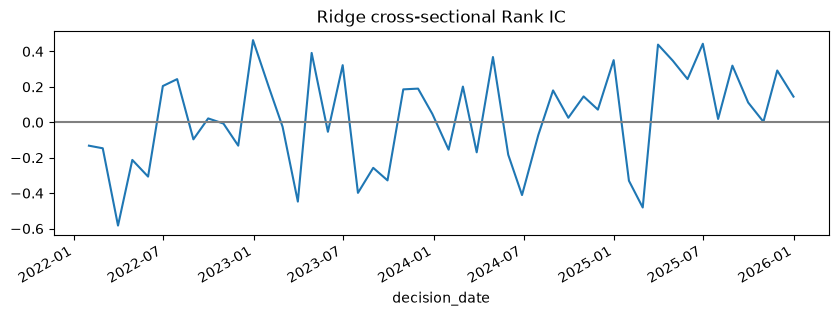

In [6]:
test60=s60[(s60.decision_date>=test_start)&(s60.decision_date<test_end)&s60.target_forward_return.notna()].copy()
test60['prediction']=model.predict(test60[FEATURES])
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
prediction_metrics={'test_mse':mean_squared_error(test60.target_forward_return,test60.prediction),'test_mae':mean_absolute_error(test60.target_forward_return,test60.prediction),'test_r2':r2_score(test60.target_forward_return,test60.prediction)}
monthly_ic=test60.groupby('decision_date').apply(lambda g:g.prediction.corr(g.target_forward_return,method='spearman'),include_groups=False).rename('rank_ic')
print(prediction_metrics,'Mean rank IC:',monthly_ic.mean())
plt.figure(figsize=(10,3));monthly_ic.plot(title='Ridge cross-sectional Rank IC');plt.axhline(0,color='gray');plt.show()

## 5. Cumulative net return, annual net return, and individual holdings

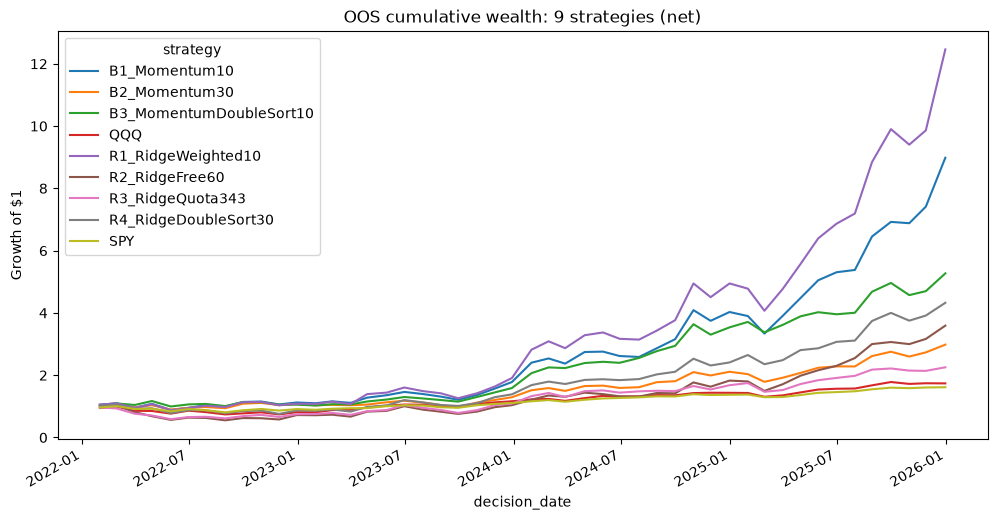

strategy,B1_Momentum10,B2_Momentum30,B3_MomentumDoubleSort10,QQQ,R1_RidgeWeighted10,R2_RidgeFree60,R3_RidgeQuota343,R4_RidgeDoubleSort30,SPY
decision_date,,,,,,,,,
2022,12.33,7.04,5.63,-18.79,8.42,-28.00,-25.35,-13.03,-8.82
2023,58.61,20.77,50.35,43.23,76.25,44.07,45.45,59.36,21.42
2024,126.14,63.29,122.68,23.34,158.85,76.18,54.62,73.88,23.86
2025,122.99,41.24,49.00,21.10,151.93,96.55,34.25,79.48,17.72


,strategy,decision_date,ticker,target_weight,stock_period_return,gross_contribution
0,B1_Momentum10,2022-01-31,DVN,0.1,0.193317,0.019332
1,B1_Momentum10,2022-01-31,FTNT,0.1,0.161865,0.016187
2,B1_Momentum10,2022-01-31,NUE,0.1,0.285853,0.028585
3,B1_Momentum10,2022-01-31,NVDA,0.1,-0.032386,-0.003239
4,B1_Momentum10,2022-01-31,BX,0.1,-0.050178,-0.005018
5,B1_Momentum10,2022-01-31,F,0.1,-0.155264,-0.015526
6,B1_Momentum10,2022-01-31,ON,0.1,0.053598,0.005360
7,B1_Momentum10,2022-01-31,FANG,0.1,0.118971,0.011897
8,B1_Momentum10,2022-01-31,KKR,0.1,-0.161596,-0.016160
9,B1_Momentum10,2022-01-31,APA,0.1,0.099031,0.009903


,strategy,decision_date,ticker,action,pretrade_weight,target_weight,delta_weight
6041,R4_RidgeDoubleSort30,2025-11-28,DECK,BUY,0.000000,0.1,0.100000
6042,R4_RidgeDoubleSort30,2025-11-28,GLW,BUY,0.000000,0.1,0.100000
6043,R4_RidgeDoubleSort30,2025-11-28,MRNA,EXIT,0.100179,0.0,-0.100179
6044,R4_RidgeDoubleSort30,2025-12-31,QCOM,BUY,0.000000,0.1,0.100000
6045,R4_RidgeDoubleSort30,2025-12-31,HOOD,EXIT,0.089381,0.0,-0.089381
6046,R4_RidgeDoubleSort30,2025-12-31,BE,ADD,0.080819,0.1,0.019181
6047,R4_RidgeDoubleSort30,2025-12-31,TPR,EXIT,0.114227,0.0,-0.114227
6048,R4_RidgeDoubleSort30,2025-12-31,LITE,BUY,0.000000,0.1,0.100000
6049,R4_RidgeDoubleSort30,2025-12-31,KLAC,REDUCE,0.103319,0.1,-0.003319
6050,R4_RidgeDoubleSort30,2025-12-31,IDXX,BUY,0.000000,0.1,0.100000


In [7]:
wide=returns.pivot(index='decision_date',columns='strategy',values='net_return').sort_index()
assert wide.notna().all().all()
(1+wide).cumprod().plot(figsize=(12,6),title='OOS cumulative wealth: 9 strategies (net)');plt.ylabel('Growth of $1');plt.show()
annual=(1+wide).groupby(wide.index.year).prod()-1
display((annual*100).round(2))
display(holdings.head(20))
display(trades.tail(20))

## 6. Save reproducible outputs

In [8]:
OUT=PROJECT_ROOT/'outputs'/'ridge_nine_strategies'/FREQUENCY
OUT.mkdir(parents=True,exist_ok=True)
for name,frame in [('strategy_summary',summary),('period_returns',returns),('annual_returns',annual),('holdings',holdings),('trades',trades),('validation_grid',grid),('screening_audit',pd.DataFrame(audit))]:frame.to_csv(OUT/f'{name}.csv',index=True if name=='annual_returns' else False)
(OUT/'fit_info.json').write_text(json.dumps({**fit_info,'frequency':FREQUENCY,'cost_bps':COST_BPS,'test_start':'2022-01-01','test_end_exclusive':'2026-01-01','screening':'60 momentum-only candidates for Ridge training; original 3x3 30-stock R4'},indent=2))
print('Saved:',OUT)
test60.to_csv(OUT/'ridge_test60_predictions.csv',index=False)
monthly_ic.to_csv(OUT/'ridge_rank_ic.csv')
(OUT/'prediction_metrics.json').write_text(json.dumps(prediction_metrics,indent=2))

Saved: /Users/hc/Desktop/NUS DSML/DSA 5205/Project2/DSA-5205/DSA5205_Project2_Pipeline/outputs/ridge_nine_strategies/monthly


109